<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Normalization | Preparing Survey Compensation for Comparison**
**IBM Skills Network guided lab | Personalized portfolio edition**


### Project overview
Imagine comparing annual salaries across thousands of developer survey responses. Before making meaningful comparisons, we need to check the data for duplicate records, missing answers, and very different numerical scales.

In this lab, I prepare a developer survey dataset and explore two ways to rescale annual compensation: Min-Max scaling and Z-score standardization. I keep the original values alongside the transformed ones so readers can see what changes.

**Main question:** How can we prepare compensation data for comparison while being clear about the assumptions and limitations of the cleaning steps?

**Workflow:** Load survey data → Remove duplicates → Review missing values → Fill selected gaps → Scale compensation → Compare distributions.

**Tools and skills:** Python, Pandas, Matplotlib, duplicate detection, missing-value handling, Min-Max scaling, Z-scores, and data interpretation.

This is an IBM Skills Network guided exercise with added explanations and portfolio framing. It is not an independent salary-market study.

Estimated time needed: **30** minutes


### Objectives


In this lab, you will perform the following:
- Identify duplicate rows and remove them.
- Check and handle missing values in key columns.
- Identify and normalize compensation-related columns.
- Visualize the effect of normalization techniques on data distributions.

-----


### Hands on Lab


#### Step 1: Install and Import Libraries


In [1]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 110.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 129.1 MB/s eta 0:00:00

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/9.9 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 120.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/5.4 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 88.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.5 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 103.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/6.9 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 90.7 MB/s eta 0:00:00

   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [pillow]
   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [pillow]
   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [pillow]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
  

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

### Step 2: Load the Dataset into a DataFrame


The dataset contains developer survey responses. Each row represents a record and each column describes an answer or attribute. We use the <code>pandas.read_csv()</code> function for reading CSV files. 

The original lab uses a course-hosted CSV. The results below reflect the notebook's saved run, not a new live download.

The functions below will download the dataset into your browser:


In [4]:
file_path ="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv"

df = pd.read_csv(file_path)

# Display the first few rows to check if data is loaded correctly
print(df.head())


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

In [ ]:
#df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv")

### Section 1: Handling Duplicates
##### Task 1: Identify and remove duplicate rows.


If an identical survey record appears twice, it could be counted twice in later calculations. duplicated() checks for repeated full rows, and drop_duplicates() keeps one copy.

In [6]:
## Write your code here
duplicate_rows = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

df = df.drop_duplicates().reset_index(drop=True)
print("Dataset size after removing duplicates:",df.shape)

Number of duplicate rows: 10Dataset size after removing duplicates: (65437, 114)

Saved result: The notebook identifies 10 exact duplicates, leaving 65,437 rows and 114 columns.

This only identifies rows that match in every column. It does not prove that each remaining row represents a unique person.

### Section 2: Handling Missing Values
##### Task 2: Identify missing values in `CodingActivities`.


Some survey respondents may leave questions blank. Before deciding how to handle those gaps, I count missing entries in CodingActivities.

**Saved result:** 10,971 records have no value in this column. This tells us how many answers are missing, but not why they are missing.

In [7]:
## Write your code here
missing_value = df['CodingActivities'].isnull().sum()
print("Missing values in CodingActivities:", missing_value)

Missing values in CodingActivities: 10971

##### Task 3: Impute missing values in CodingActivities with forward-fill.


In [9]:
## Write your code here
df['CodingActivities'] = df['CodingActivities'].ffill()

print("Remaining missing rows in 'CodingActivities':", df['CodingActivities'].isnull().sum())

Remaining missing rows in 'CodingActivities': 0

**Note**:  Before normalizing ConvertedCompYearly, ensure that any missing values (NaN) in this column are handled appropriately. You can choose to either drop the rows containing NaN or replace the missing values with a suitable statistic (e.g., median or mean).


### Section 3: Normalizing Compensation Data
##### Task 4: Identify compensation-related columns, such as ConvertedCompYearly.
Normalization is commonly applied to compensation data to bring values within a comparable range. To focus the analysis, the code searches for column names containing Comp. It then fills missing values in ConvertedCompYearly using the median.

The median is often less influenced by extreme values than the mean. Still, replacing missing salaries with a single number can create an artificial concentration around that value and change later statistics.

In [11]:
## Write your code here
comp_columns = [col 
                for col in df.columns if 'Comp' in col]
print("Compensation columns identified:", comp_columns)

comp_median = df['ConvertedCompYearly'].median()
df['ConvertedCompYearly'] = df['ConvertedCompYearly'].fillna(comp_median)
print("Remaining missing:", df['ConvertedCompYearly'].isnull().sum())

Compensation columns identified: ['CompTotal', 'AIComplex', 'ConvertedCompYearly']
Remaining missing: 0

**Saved result:** The code reports 0 remaining missing values in ConvertedCompYearly after filling them.

The broad name search also returns AIComplex, which is not necessarily a compensation variable. Column names should be checked against the survey's data dictionary before interpretation.

##### Task 5: Normalize ConvertedCompYearly using Min-Max Scaling.
Min-Max scaling converts the smallest salary to 0 and the largest to 1, with other values placed proportionally between them. This helps compare variables that use different numerical units.

**How to read it:** A scaled value near 0 means the salary is closer to the minimum observed value, not that the person earns 0 dollars.

**Caution:** An extremely high maximum can compress most ordinary salaries into a very small range. The saved results show that a salary of 65,000 becomes approximately 0.003998, suggesting the maximum has a strong effect on the scale.

In [12]:
## Write your code here
comp_min = df['ConvertedCompYearly'].min()
comp_max = df['ConvertedCompYearly'].max()

df['ConvertedCompYearly_norm'] = (df['ConvertedCompYearly'] - comp_min) / (comp_max - comp_min)
print(df[['ConvertedCompYearly', 'ConvertedCompYearly_norm']].head())

   ConvertedCompYearly  ConvertedCompYearly_norm
0              65000.0                  0.003998
1              65000.0                  0.003998
2              65000.0                  0.003998
3              65000.0                  0.003998
4              65000.0                  0.003998

##### Task 6: Apply Z-score Normalization to `ConvertedCompYearly`.

A Z-score shows how far a value lies above or below the dataset's mean, measured in standard deviations.
- 0 means the value equals the mean.
- Positive values are above the mean.
- Negative values are below the mean.
In the saved run, a salary of 65,000 has a Z-score of approximately = 0.0675. This is slightly below the calculated mean, not a judgment about whether that salary is good or bad.

Unlike Min-Max scaling, Z-scores are not limited to 0-1. Extreme salaries can still strongly affect the mean and standard deviation.

In [13]:
## Write your code here
comp_mean = df['ConvertedCompYearly'].mean()
comp_std = df['ConvertedCompYearly'].std()

df['ConvertedCompYearly_Zscore'] = (df['ConvertedCompYearly'] - comp_mean) / comp_std
print(df[['ConvertedCompYearly', 'ConvertedCompYearly_Zscore']].head())

   ConvertedCompYearly  ConvertedCompYearly_Zscore
0              65000.0                   -0.067513
1              65000.0                   -0.067513
2              65000.0                   -0.067513
3              65000.0                   -0.067513
4              65000.0                   -0.067513

### Section 4: Visualization of Normalized Data
##### Task 7: Visualize the distribution of `ConvertedCompYearly`, `ConvertedCompYearly_Normalized`, and `ConvertedCompYearly_Zscore`

The three histograms show the same underlying salary values, expressed in different units. The first uses annual compensation, the second uses Min-Max values, and the third uses standard-deviation units.

Look for the overall concentration of observations and the long tail of unusually high salaries. Scaling changes the axis, but it does not remove outliers or make a skewed distribution normal.

**Chart note:** The original code limits the visible x-axis range for readability. This hides some extreme values from view; it does not delete them from the dataset or exclude them from the scaling calculations.


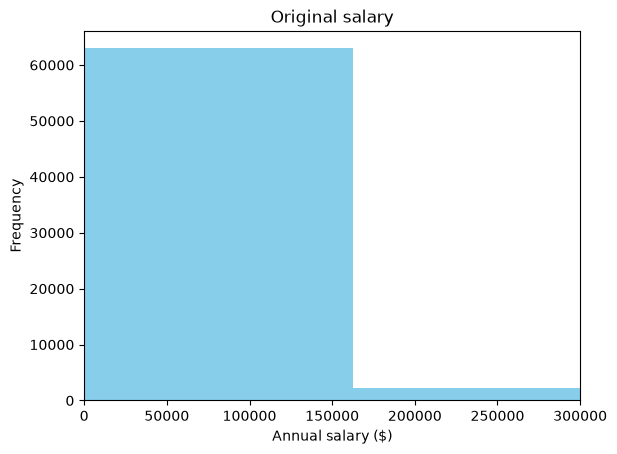

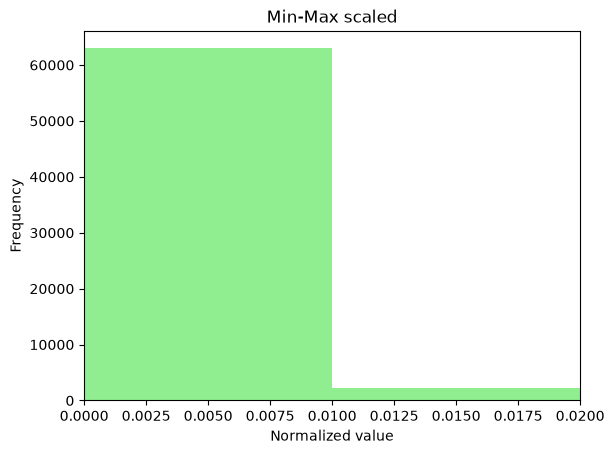

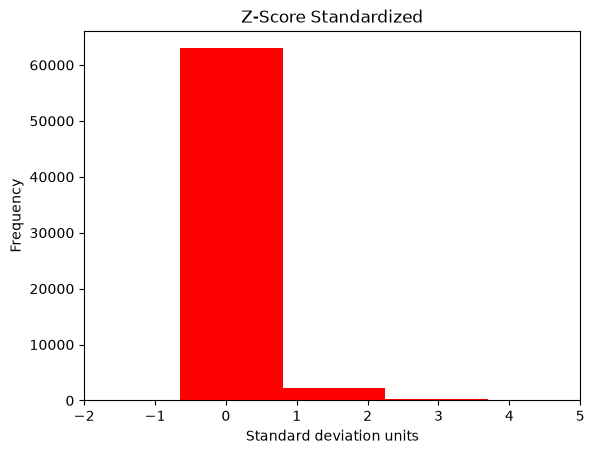

In [17]:
## Write your code here
df['ConvertedCompYearly'].plot(kind='hist', bins=100, color='skyblue')
plt.title("Original salary")
plt.xlim(0, 300000)
plt.xlabel("Annual salary ($)")
plt.show()

df['ConvertedCompYearly_norm'].plot(kind='hist', bins=100, color='lightgreen')
plt.title("Min-Max scaled")
plt.xlim(0, 0.02)
plt.xlabel("Normalized value")
plt.show()

df['ConvertedCompYearly_Zscore'].plot(kind='hist', bins=100, color='red')
plt.title("Z-Score Standardized")
plt.xlim(-2, 5)
plt.xlabel("Standard deviation units")
plt.show()

### Key findings and interpretation
- The saved run removes 10 exact duplicate rows, leaving 65,437 records.
- CodingActivities initially has 10,971 missing entries; forward-fill leaves none, although its suitability for independent survey respondents is questionable.
- Missing ConvertedCompYearly values are filled with the median before scaling.
- Min-Max scaling places annual compensation on a 0–1 range, while Z-scores describe distance from the mean in standard deviations.
- The histograms help compare representations of salary, but changing the scale does not resolve skewness or outliers.

### Limitations and next steps
This is a guided data-preparation exercise, not a salary benchmarking report. The survey may not represent all developers, and the missing-data treatments introduce assumptions. The maximum salary can make Min-Max values hard to interpret, while unusually high salaries can affect Z-scores.

For a stronger analysis, I would examine missingness before imputation, check the compensation data for extreme values, review the survey data dictionary, compare results before and after imputation, and consider robust or logarithmic transformations where justified.

### Skills demonstrated
- Data quality: Exact duplicate checks and missing-value counts
- Data preparation: Forward-fill and median imputation
- Feature scaling: Min-Max normalization and Z-score standardization
- Visualization: Histograms and axis interpretation
- Analytical judgment: Identifying where a valid technique may still be inappropriate for the dataset

*Portfolio attribution: Original exercise, data, and code are from IBM Skills Network. Project context and explanatory interpretation were added for accessibility. Saved outputs were not independently rerun.*

Copyright © IBM Corporation. All rights reserved.
